# 07 | PLSA topic-mixture and boundary experiment

This experiment compares how three PLSA configurations represent synthetic documents made from known token-source proportions:

1. The best full-data restart, used as the baseline model.
2. A five-restart ensemble trained on the full training set.
3. A five-member bootstrap ensemble trained on shared-size resamples of the training set.

The models use the same training vocabulary, source documents, synthetic mixtures, and held-out-by-split baseline setup. Topic IDs are arbitrary and can differ between fits, so we identify each model's source-associated topic from that model's own training document-topic distributions before comparing probabilities. For each ensemble member set, we average the aligned source-associated probabilities for the same synthetic document. The study is PLSA-only because this question concerns inferred topic probabilities.


## 1. Settings and imports

The notebook reads the shared preprocessed corpus. The split, source categories, mixture ratios, repeat count, and model settings are experiment-specific.


In [25]:
import json
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.model_selection import train_test_split

REPOSITORY_ROOT = Path.cwd() if (Path.cwd() / 'src').is_dir() else Path.cwd().parent
if str(REPOSITORY_ROOT) not in sys.path:
    sys.path.insert(0, str(REPOSITORY_ROOT))

from src.plsa_model import train_plsa_restarts
from src.synthetic_data import make_mixed_document

SEED = 42
TEST_SIZE = 0.25
K = 5
N_RESTARTS = 5
BAGGING_ESTIMATORS = 5
MAX_ITER = 100
TOLERANCE = 1e-4
MAX_FEATURES = 3000
MIN_DF = 3
MAX_DF = 0.90
FOLD_IN_ITERATIONS = 100
BOOTSTRAP_SEED = SEED + 500
MIXTURE_SEED = SEED + 77
SOURCE_CATEGORY_A = 'rec.sport.baseball'
SOURCE_CATEGORY_B = 'talk.politics.misc'
SOURCE_RATIOS_A = [0.0, 0.1, 0.3, 0.5, 0.7, 0.9, 1.0]
REPLICATES_PER_RATIO = 30
TOKENS_PER_MIXTURE = 300
DATA_PATH = REPOSITORY_ROOT / 'data' / '20news_preprocessed.npz'
OUTPUT_DIR = REPOSITORY_ROOT / 'results' / 'topic_boundary_experiment'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print(f'Repository: {REPOSITORY_ROOT.resolve()}')
print(f'Results folder: {OUTPUT_DIR.resolve()}')
print(f'PLSA K={K}; full-data restarts={N_RESTARTS}; bootstrap members={BAGGING_ESTIMATORS}')


Repository: F:\OneDrive\Academics\bits\IR\Project\Local
Results folder: F:\OneDrive\Academics\bits\IR\Project\Local\results\topic_boundary_experiment
PLSA K=5; full-data restarts=5; bootstrap members=5


## 2. Load the all-20 corpus and make the baseline-aligned split

We retain all 20 categories and use the same stratified 75/25 split as the PLSA baseline. The held-out partition is unused here; source documents for the mixtures are selected from the training partition. Category labels select those source documents and later identify the corresponding topics, but they are not passed to PLSA training.


In [26]:
if not DATA_PATH.exists():
    raise FileNotFoundError(f'Missing {DATA_PATH}. Run src/preprocessing.ipynb first.')
with np.load(DATA_PATH, allow_pickle=False) as corpus:
    documents = corpus['documents'].tolist()
    labels = corpus['labels'].astype(np.int64, copy=False)
    category_names = corpus['category_names'].tolist()

for category in [SOURCE_CATEGORY_A, SOURCE_CATEGORY_B]:
    if category not in category_names:
        raise ValueError(f'Source category is absent from the corpus: {category}')
class_a = category_names.index(SOURCE_CATEGORY_A)
class_b = category_names.index(SOURCE_CATEGORY_B)
docs_train, docs_test, y_train, y_test = train_test_split(
    documents, labels, test_size=TEST_SIZE,
    random_state=SEED, stratify=labels,
)
print(f'Corpus: {len(documents):,} documents; categories: {len(category_names)}')
print(f'Train/test split: {len(docs_train):,}/{len(docs_test):,}')
print('Training source-category counts:', {
    SOURCE_CATEGORY_A: int(np.count_nonzero(y_train == class_a)),
    SOURCE_CATEGORY_B: int(np.count_nonzero(y_train == class_b)),
})


Corpus: 18,846 documents; categories: 20
Train/test split: 14,134/4,712
Training source-category counts: {'rec.sport.baseball': 745, 'talk.politics.misc': 581}


## 3. Fit the shared training count vocabulary

A single count vocabulary is fitted on the training text and reused by the full-data and bootstrap PLSA fits. This keeps every topic-word distribution and synthetic mixture in the same feature space. The bootstrap models still see different training-row samples.


In [27]:
from sklearn.feature_extraction.text import CountVectorizer
count_vectorizer = CountVectorizer(
    lowercase=False, tokenizer=str.split, token_pattern=None,
    max_features=MAX_FEATURES, min_df=MIN_DF, max_df=MAX_DF,
    dtype=np.float64,
)
X_train = count_vectorizer.fit_transform(docs_train)
nonempty_train = np.asarray(X_train.sum(axis=1)).ravel() > 0
print('Training count matrix:', X_train.shape)
print('Empty training documents:', int((~nonempty_train).sum()))


Training count matrix: (14134, 3000)
Empty training documents: 457


## 4. Fit the baseline PLSA model and full-data restart ensemble

We fit five random initializations on the complete training matrix. The model with the largest training log-likelihood is the single-model baseline. The same five fits also form the full-data restart group; this lets us compare the baseline with probability aggregation across different initializations without changing the training documents.


In [28]:
best_plsa, restart_runs = train_plsa_restarts(
    X_train, n_topics=K, n_restarts=N_RESTARTS,
    max_iter=MAX_ITER, tol=TOLERANCE, base_seed=SEED,
)
restart_models = [model for model, _ in restart_runs]
restart_summary = pd.DataFrame([
    {'restart': i + 1, 'seed': SEED + i, 'iterations': model.n_iter_,
     'training_log_likelihood': float(log_likelihood),
     'is_baseline_best_restart': model is best_plsa}
    for i, (model, log_likelihood) in enumerate(restart_runs)
])
display(restart_summary)


Restart 1: final training log-likelihood=-5995748.434, iterations=43
Restart 2: final training log-likelihood=-5993380.381, iterations=50
Restart 3: final training log-likelihood=-5989043.226, iterations=51
Restart 4: final training log-likelihood=-6003355.064, iterations=48
Restart 5: final training log-likelihood=-5995924.901, iterations=54
Selected best training likelihood: -5989043.226


,restart,seed,iterations,training_log_likelihood,is_baseline_best_restart
0,1,42,43,-5.995748e+06,False
1,2,43,50,-5.993380e+06,False
2,3,44,51,-5.989043e+06,True
3,4,45,48,-6.003355e+06,False
4,5,46,54,-5.995925e+06,False


## 5. Fit the bootstrap PLSA ensemble

Each bootstrap member draws as many training-row indices as there are training documents, with replacement. We retain the sampled labels alongside the resampled count rows so we can identify source-associated topics within each member's own fitted topic space.


In [29]:
bootstrap_rng = np.random.default_rng(BOOTSTRAP_SEED)
bootstrap_indices_list = [
    bootstrap_rng.integers(0, X_train.shape[0], size=X_train.shape[0])
    for _ in range(BAGGING_ESTIMATORS)
]
bootstrap_models = []
bootstrap_training_labels = []
bootstrap_training_counts = []
bootstrap_summary_rows = []
for member, indices in enumerate(bootstrap_indices_list):
    bootstrap_X = X_train[indices]
    bootstrap_y = y_train[indices]
    model = train_plsa_restarts(
        bootstrap_X, n_topics=K, n_restarts=1,
        max_iter=MAX_ITER, tol=TOLERANCE,
        base_seed=SEED + 1000 + member,
    )[0]
    bootstrap_models.append(model)
    bootstrap_training_labels.append(bootstrap_y)
    bootstrap_training_counts.append(bootstrap_X)
    bootstrap_summary_rows.append({
        'member': member + 1,
        'sampled_rows': len(indices),
        'unique_training_documents': int(np.unique(indices).size),
        'iterations': model.n_iter_,
        'bootstrap_training_log_likelihood': float(model.log_likelihoods[-1]),
    })
bootstrap_summary = pd.DataFrame(bootstrap_summary_rows)
display(bootstrap_summary)


Restart 1: final training log-likelihood=-6063509.517, iterations=35
Selected best training likelihood: -6063509.517
Restart 1: final training log-likelihood=-6084545.089, iterations=44
Selected best training likelihood: -6084545.089
Restart 1: final training log-likelihood=-5968923.192, iterations=42
Selected best training likelihood: -5968923.192
Restart 1: final training log-likelihood=-6198530.540, iterations=36
Selected best training likelihood: -6198530.54
Restart 1: final training log-likelihood=-5830869.966, iterations=47
Selected best training likelihood: -5830869.966


,member,sampled_rows,unique_training_documents,iterations,bootstrap_training_log_likelihood
0,1,14134,8921,35,-6.063510e+06
1,2,14134,8943,44,-6.084545e+06
2,3,14134,8899,42,-5.968923e+06
3,4,14134,8925,36,-6.198531e+06
4,5,14134,8930,47,-5.830870e+06


## 6. Associate each fitted model's topics with the source categories

Topic numbers have no shared meaning across independent fits. For every model, we therefore find the topic with the highest mean probability among non-empty training documents from each source category. We use these within-model topic associations before averaging mixture probabilities across restart or bootstrap members.


In [30]:
model_groups = {
    'PLSA baseline (best full-data restart)': [
        ('best_restart', best_plsa, y_train, X_train),
    ],
    'PLSA full-data restart ensemble (5 members)': [
        (f'restart_{i + 1}', model, y_train, X_train)
        for i, model in enumerate(restart_models)
    ],
    'PLSA bootstrap ensemble (5 members)': [
        (f'bootstrap_{i + 1}', model, bootstrap_training_labels[i], bootstrap_training_counts[i])
        for i, model in enumerate(bootstrap_models)
    ],
}
source_topic_rows = []
associated_topics = {}
for family, members in model_groups.items():
    associated_topics[family] = {}
    for member_name, model, member_labels, member_counts in members:
        member_nonempty = np.asarray(member_counts.sum(axis=1)).ravel() > 0
        theta_fit = model.transform()
        associated_topics[family][member_name] = {}
        for source_name, class_id in [(SOURCE_CATEGORY_A, class_a), (SOURCE_CATEGORY_B, class_b)]:
            category_mask = (np.asarray(member_labels) == class_id) & member_nonempty
            if not category_mask.any():
                raise ValueError(f'No non-empty {source_name} documents for {family}/{member_name}.')
            class_topic_mean = theta_fit[category_mask].mean(axis=0)
            topic_id = int(np.argmax(class_topic_mean))
            associated_topics[family][member_name][source_name] = topic_id
            source_topic_rows.append({
                'model_family': family, 'member': member_name,
                'source_category': source_name, 'associated_topic': topic_id,
                'mean_probability_in_source_category': float(class_topic_mean[topic_id]),
                'nonempty_source_training_documents': int(category_mask.sum()),
            })
source_topic_summary = pd.DataFrame(source_topic_rows)
display(source_topic_summary)
for family, members in associated_topics.items():
    shared_topic_members = [
        member for member, mapping in members.items()
        if mapping[SOURCE_CATEGORY_A] == mapping[SOURCE_CATEGORY_B]
    ]
    if shared_topic_members:
        print(f'Caution: {family} maps both source categories to the same topic for: {shared_topic_members}')


,model_family,member,source_category,associated_topic,mean_probability_in_source_category,nonempty_source_training_documents
0,PLSA baseline (best full-data restart),best_restart,rec.sport.baseball,1,0.728709,698
1,PLSA baseline (best full-data restart),best_restart,talk.politics.misc,2,0.414415,561
2,PLSA full-data restart ensemble (5 members),restart_1,rec.sport.baseball,1,0.670383,698
3,PLSA full-data restart ensemble (5 members),restart_1,talk.politics.misc,3,0.330630,561
4,PLSA full-data restart ensemble (5 members),restart_2,rec.sport.baseball,4,0.736387,698
5,PLSA full-data restart ensemble (5 members),restart_2,talk.politics.misc,2,0.463444,561
6,PLSA full-data restart ensemble (5 members),restart_3,rec.sport.baseball,1,0.728709,698
7,PLSA full-data restart ensemble (5 members),restart_3,talk.politics.misc,2,0.414415,561
8,PLSA full-data restart ensemble (5 members),restart_4,rec.sport.baseball,1,0.552806,698
9,PLSA full-data restart ensemble (5 members),restart_4,talk.politics.misc,2,0.420198,561


Caution: PLSA bootstrap ensemble (5 members) maps both source categories to the same topic for: ['bootstrap_4']


## 7. Generate the same synthetic mixtures for every PLSA configuration

At each source-A ratio, we generate repeated 300-token documents using the same source-document sampling procedure. Every PLSA model receives each generated document. For each member, we record the probability of its own baseball-associated topic and politics-associated topic. We then average those aligned probabilities across members to form the restart and bootstrap ensemble estimates.

The reported ratio is the fraction of sampled tokens drawn from source-A versus source-B documents. It is not a guarantee that the same fraction of tokens is uniquely about that category.


In [31]:
mixture_rng = np.random.default_rng(MIXTURE_SEED)
mixture_member_rows = []
for ratio_a in SOURCE_RATIOS_A:
    for replicate in range(REPLICATES_PER_RATIO):
        mixed_counts = make_mixed_document(
            X_train, y_train, class_a, class_b,
            ratio_a, mixture_rng, n_tokens=TOKENS_PER_MIXTURE,
        )
        for family, members in model_groups.items():
            for member_name, model, _, _ in members:
                estimated_theta = model.fold_in(
                    mixed_counts, max_iter=FOLD_IN_ITERATIONS,
                )[0]
                mapping = associated_topics[family][member_name]
                mixture_member_rows.append({
                    'model_family': family, 'member': member_name,
                    'sampled_source_a_token_ratio': ratio_a,
                    'sampled_source_b_token_ratio': 1 - ratio_a,
                    'replicate': replicate + 1,
                    'estimated_source_a_topic_probability': float(estimated_theta[mapping[SOURCE_CATEGORY_A]]),
                    'estimated_source_b_topic_probability': float(estimated_theta[mapping[SOURCE_CATEGORY_B]]),
                })
mixture_member_results = pd.DataFrame(mixture_member_rows)

# Average aligned member probabilities within each generated mixture document.
mixture_results = mixture_member_results.groupby(
    ['model_family', 'sampled_source_a_token_ratio',
     'sampled_source_b_token_ratio', 'replicate'], as_index=False,
).agg(
    estimated_source_a_topic_probability=('estimated_source_a_topic_probability', 'mean'),
    estimated_source_b_topic_probability=('estimated_source_b_topic_probability', 'mean'),
)
mixture_summary = mixture_results.groupby(
    ['model_family', 'sampled_source_a_token_ratio', 'sampled_source_b_token_ratio'],
    as_index=False,
).agg(
    source_a_topic_mean=('estimated_source_a_topic_probability', 'mean'),
    source_a_topic_std=('estimated_source_a_topic_probability', 'std'),
    source_b_topic_mean=('estimated_source_b_topic_probability', 'mean'),
    source_b_topic_std=('estimated_source_b_topic_probability', 'std'),
)
print('Mixture estimates averaged within each model family and source ratio:')
display(mixture_summary.round(4))


Mixture estimates averaged within each model family and source ratio:


,model_family,sampled_source_a_token_ratio,sampled_source_b_token_ratio,source_a_topic_mean,source_a_topic_std,source_b_topic_mean,source_b_topic_std
0,PLSA baseline (best full-data restart),0.0,1.0,0.1411,0.2061,0.4408,0.3286
1,PLSA baseline (best full-data restart),0.1,0.9,0.2045,0.1345,0.3198,0.2014
2,PLSA baseline (best full-data restart),0.3,0.7,0.3227,0.1951,0.3651,0.2473
3,PLSA baseline (best full-data restart),0.5,0.5,0.4194,0.1977,0.3092,0.2153
4,PLSA baseline (best full-data restart),0.7,0.3,0.5578,0.2326,0.2268,0.2189
5,PLSA baseline (best full-data restart),0.9,0.1,0.6955,0.1971,0.1560,0.1499
6,PLSA baseline (best full-data restart),1.0,0.0,0.6765,0.2727,0.1007,0.1342
7,PLSA bootstrap ensemble (5 members),0.0,1.0,0.2301,0.1594,0.3815,0.0678
8,PLSA bootstrap ensemble (5 members),0.1,0.9,0.2805,0.1202,0.3742,0.0617
9,PLSA bootstrap ensemble (5 members),0.3,0.7,0.3635,0.1421,0.3552,0.0662


## 8. Compare topic-mixture responses

The two panels are stacked vertically for readability. Each line shows the mean probability across generated mixtures; error bars show the standard deviation across mixture replicates after averaging aligned PLSA member probabilities. The diagonal is an ideal reference, not an assumption that source-token proportions must equal latent-topic probabilities.


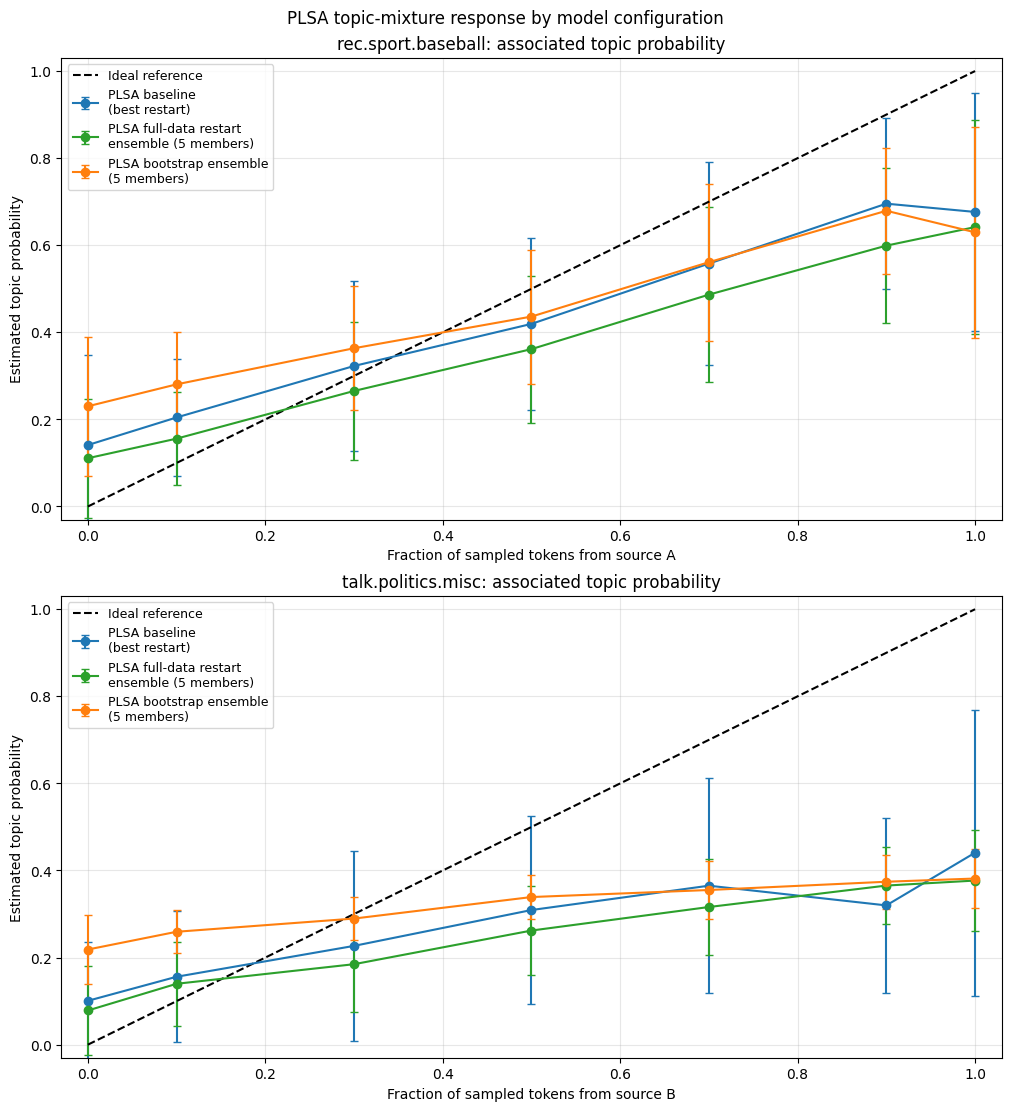

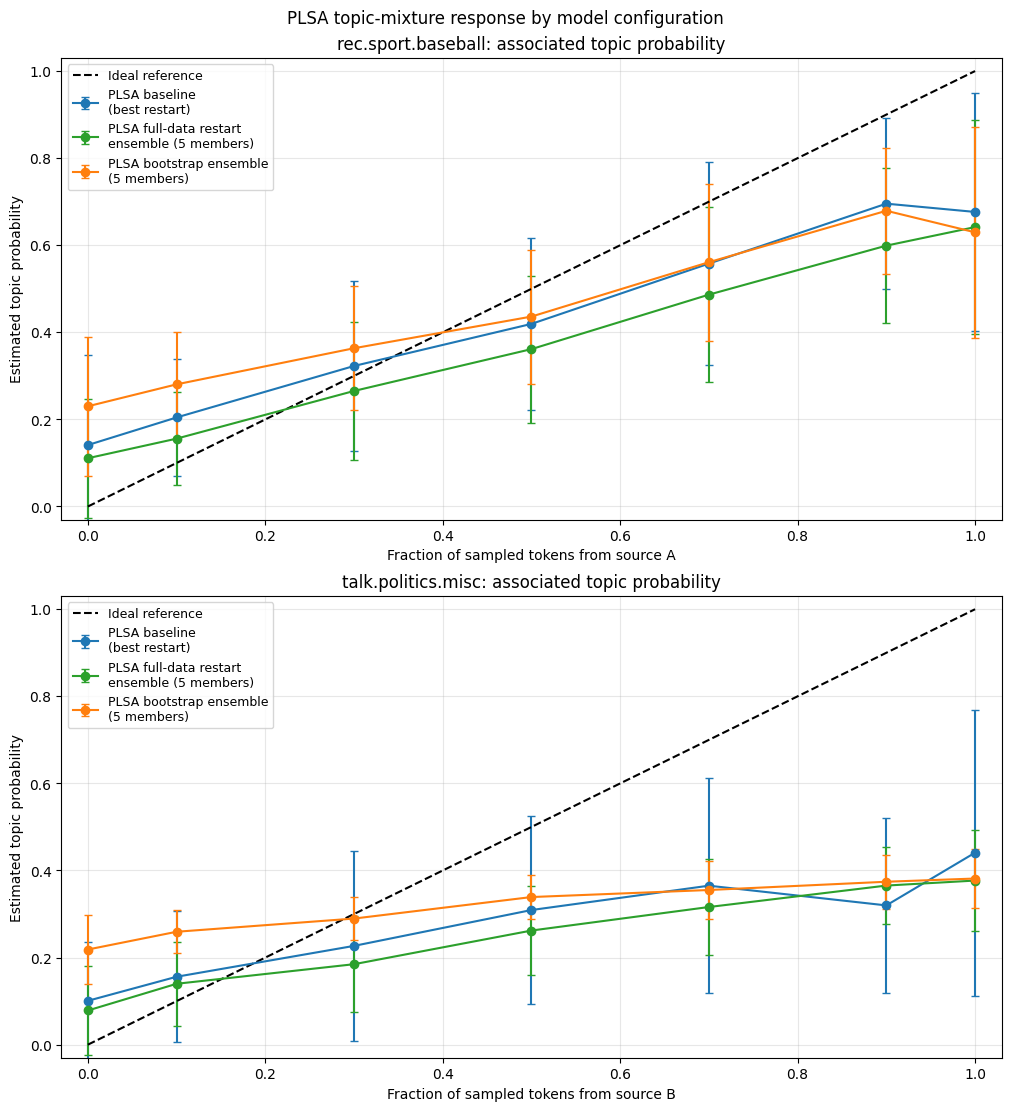

In [32]:
family_labels = {
    'PLSA baseline (best full-data restart)': 'PLSA baseline\n(best restart)',
    'PLSA full-data restart ensemble (5 members)': 'PLSA full-data restart\nensemble (5 members)',
    'PLSA bootstrap ensemble (5 members)': 'PLSA bootstrap ensemble\n(5 members)',
}
colors = {
    'PLSA baseline (best full-data restart)': 'tab:blue',
    'PLSA full-data restart ensemble (5 members)': 'tab:green',
    'PLSA bootstrap ensemble (5 members)': 'tab:orange',
}
mixture_fig, axes = plt.subplots(2, 1, figsize=(10, 11), constrained_layout=True)
for family in model_groups:
    family_data = mixture_summary[mixture_summary['model_family'] == family]
    axes[0].errorbar(
        family_data['sampled_source_a_token_ratio'],
        family_data['source_a_topic_mean'], yerr=family_data['source_a_topic_std'],
        marker='o', capsize=3, color=colors[family], label=family_labels[family],
    )
    axes[1].errorbar(
        family_data['sampled_source_b_token_ratio'],
        family_data['source_b_topic_mean'], yerr=family_data['source_b_topic_std'],
        marker='o', capsize=3, color=colors[family], label=family_labels[family],
    )
for ax, category, source in [
    (axes[0], SOURCE_CATEGORY_A, 'A'),
    (axes[1], SOURCE_CATEGORY_B, 'B'),
]:
    ax.plot([0, 1], [0, 1], 'k--', label='Ideal reference')
    ax.set(
        title=f'{category}: associated topic probability',
        xlabel=f'Fraction of sampled tokens from source {source}',
        ylabel='Estimated topic probability',
        xlim=(-0.03, 1.03), ylim=(-0.03, 1.03),
    )
    ax.grid(alpha=0.3)
    ax.legend(loc='best', fontsize=9)
mixture_fig.suptitle('PLSA topic-mixture response by model configuration')
display(mixture_fig)


## 9. Save outputs

The member-level estimates, per-mixture ensemble estimates, ratio summaries, within-model source-topic associations, training summaries, figure, and run configuration are saved to `results/topic_boundary_experiment/`. Rerunning this notebook replaces the previous outputs for this experiment.


In [33]:
mixture_member_results.to_csv(OUTPUT_DIR / 'mixture_estimates_by_member.csv', index=False)
mixture_results.to_csv(OUTPUT_DIR / 'mixture_estimates_by_replicate.csv', index=False)
mixture_summary.to_csv(OUTPUT_DIR / 'mixture_estimates_by_ratio.csv', index=False)
source_topic_summary.to_csv(OUTPUT_DIR / 'source_associated_topics.csv', index=False)
restart_summary.to_csv(OUTPUT_DIR / 'plsa_restart_summary.csv', index=False)
bootstrap_summary.to_csv(OUTPUT_DIR / 'plsa_bootstrap_member_summary.csv', index=False)
pd.DataFrame({
    'iteration': np.arange(1, len(best_plsa.log_likelihoods) + 1),
    'training_log_likelihood': best_plsa.log_likelihoods,
}).to_csv(OUTPUT_DIR / 'plsa_convergence.csv', index=False)
np.savez_compressed(
    OUTPUT_DIR / 'plsa_bootstrap_indices.npz',
    **{f'member_{i + 1}': indices for i, indices in enumerate(bootstrap_indices_list)},
)
mixture_fig.savefig(OUTPUT_DIR / 'topic_boundary_mixture_probabilities.png', dpi=160, bbox_inches='tight')

# Remove comparison artifacts produced by the earlier retrieval version of this notebook.
for obsolete_name in [
    'retrieval_metrics_by_query.csv',
    'retrieval_metrics_macro_average.csv',
    'retrieval_metrics_comparison.png',
]:
    obsolete_path = OUTPUT_DIR / obsolete_name
    if obsolete_path.exists():
        obsolete_path.unlink()

configuration = {
    'experiment': 'PLSA topic-mixture and boundary experiment',
    'seed': SEED, 'test_size': TEST_SIZE, 'n_topics': K,
    'full_data_restarts': N_RESTARTS,
    'bootstrap_estimators': BAGGING_ESTIMATORS,
    'bootstrap_seed': BOOTSTRAP_SEED,
    'bootstrap_sample_size': int(X_train.shape[0]),
    'bootstrap_with_replacement': True,
    'mixture_seed': MIXTURE_SEED,
    'source_categories': [SOURCE_CATEGORY_A, SOURCE_CATEGORY_B],
    'source_a_token_ratios': SOURCE_RATIOS_A,
    'replicates_per_ratio': REPLICATES_PER_RATIO,
    'tokens_per_mixture': TOKENS_PER_MIXTURE,
    'fold_in_iterations': FOLD_IN_ITERATIONS,
    'probability_aggregation': 'average source-associated topic probabilities after within-model category-based topic alignment',
    'topic_association_rule': 'largest mean training-document topic probability within each non-empty source category and model member',
    'documents': len(documents), 'training_documents': len(docs_train),
    'held_out_documents_unused_for_this_probe': len(docs_test),
}
with (OUTPUT_DIR / 'configuration.json').open('w', encoding='utf-8') as handle:
    json.dump(configuration, handle, indent=2)
print(f'Saved PLSA topic-mixture outputs to {OUTPUT_DIR.resolve()}')


Saved PLSA topic-mixture outputs to F:\OneDrive\Academics\bits\IR\Project\Local\results\topic_boundary_experiment
